<!-- Dr. Nam H. Le. drnamlabs.com, bunnyquant.com -->
# 03. Does sharpness β move the bank between two known classes of collective dynamics?

**Story.** Picture a village choosing between two opinions. In one village, each person copies one neighbour picked at random.
That is the **voter model**. A little outside noise (people who ignore the neighbours) is enough to keep both opinions alive,
and a bigger village needs *less* noise per person: the threshold falls like 1/K.
In the other village, each person adopts the **majority** of everyone. Majority rule locks in a consensus,
and a fixed fraction of noise is needed to break it, however large the village. That is the mean-field Ising picture.

Attention does both. At high β a query retrieves essentially **one** stored pattern, so it copies.
At low β it returns a **weighted average**, so it follows the majority.

**Prediction, stated before the run.** α_c · K is constant at high β (voter). α_c is constant at low β (majority).

*Example of the measurement.* For β = 2 and K = 80, P_alive crosses 0.5 between α = 0.3 and 0.4.
Interpolating in log α gives α_c. We repeat this for every (β, K).

In [1]:
# Dr. Nam H. Le. drnamlabs.com, bunnyquant.com
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
FIG = Path('figures')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
z = np.load('data/sweep_alphac.npz')
Ks, betas, alphas = z['Ks'], z['betas'], z['alphas']
P = z['p_alive']                  # (K, beta, alpha, seed)
Pm = P.mean(-1)

def alpha_c(curve, al=alphas):
    """First crossing of 0.5, linear in log alpha (alpha = 0 mapped to 1e-4)."""
    la = np.log(np.where(al > 0, al, 1e-4))
    for i in range(len(al) - 1):
        if curve[i] < 0.5 <= curve[i + 1]:
            f = (0.5 - curve[i]) / (curve[i + 1] - curve[i])
            return float(np.exp(la[i] + f * (la[i + 1] - la[i])))
    return np.nan if curve[0] < 0.5 else 0.0

AC = np.array([[alpha_c(Pm[ki, bi]) for bi in range(len(betas))] for ki in range(len(Ks))])
# bootstrap over seeds for error bars
rng = np.random.default_rng(0)
B = 300
ACb = np.full((B,) + AC.shape, np.nan)
for b in range(B):
    idx = rng.integers(P.shape[-1], size=P.shape[-1])
    Pb = P[..., idx].mean(-1)
    ACb[b] = [[alpha_c(Pb[ki, bi]) for bi in range(len(betas))] for ki in range(len(Ks))]
lo, hi = np.nanpercentile(ACb, 2.5, 0), np.nanpercentile(ACb, 97.5, 0)
print('alpha_c (rows K, cols beta)', betas)
for ki, K in enumerate(Ks):
    print(f'K={int(K):4d}', ' '.join(f'{AC[ki, bi]:.4f} [{lo[ki, bi]:.4f},{hi[ki, bi]:.4f}]' for bi in range(len(betas))))

alpha_c (rows K, cols beta) [1.5 2.  3.  4.  6. ]
K=  20 nan [nan,nan] 0.3987 [0.3826,0.4128] 0.0288 [0.0089,0.0349] 0.0013 [0.0002,0.0023] 0.0000 [0.0000,0.0000]
K=  40 0.7872 [0.7752,0.7974] 0.3776 [0.3717,0.3869] 0.0258 [0.0154,0.0313] 0.0015 [0.0010,0.0019] 0.0000 [0.0000,0.0000]
K=  80 0.7483 [0.7418,0.7553] 0.3622 [0.3559,0.3698] 0.0365 [0.0067,0.0457] 0.0009 [0.0003,0.0020] 0.0000 [0.0000,0.0000]
K= 160 0.7338 [0.7307,0.7366] 0.3675 [0.3609,0.3809] 0.0535 [0.0515,0.0555] 0.0005 [0.0004,0.0011] 0.0000 [0.0000,0.0000]


  return fnb._ureduce(a,


## P_alive(α) for every β: how the curves move with K

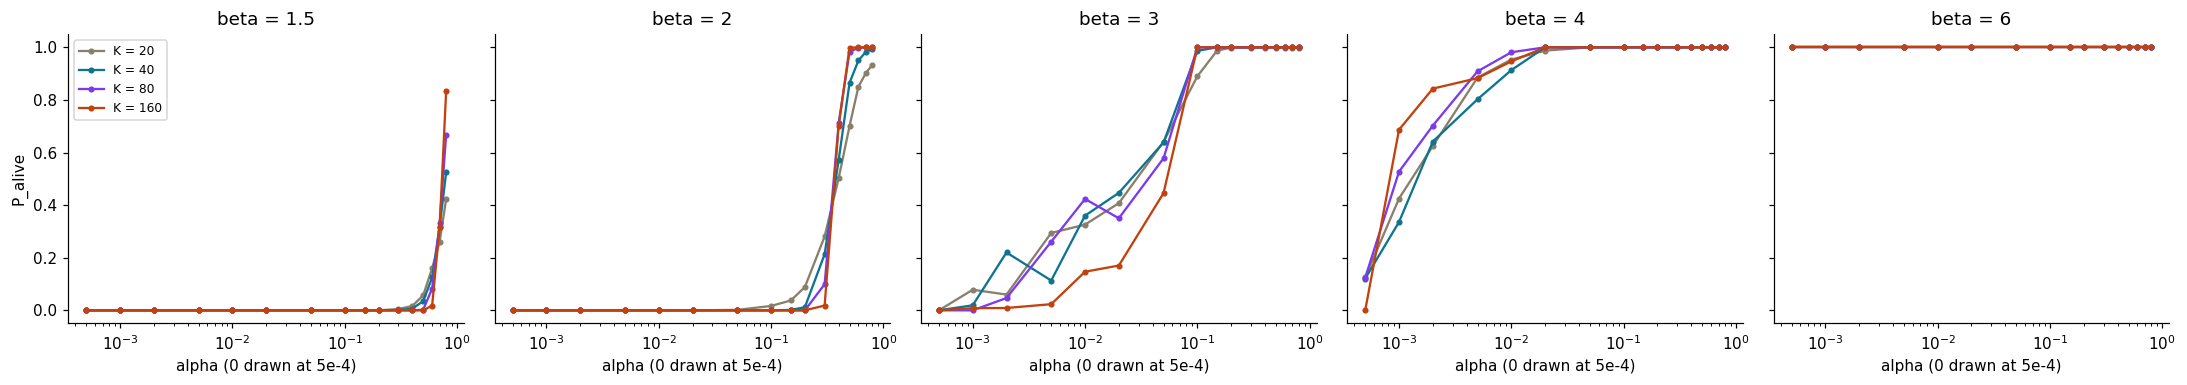

In [2]:
cols = {20: '#8a7f6a', 40: '#0e7490', 80: '#7c3aed', 160: '#c2410c'}
fig, ax = plt.subplots(1, len(betas), figsize=(4 * len(betas), 3.6), sharey=True)
for bi, b in enumerate(betas):
    for ki, K in enumerate(Ks):
        ax[bi].plot(np.where(alphas > 0, alphas, 5e-4), Pm[ki, bi], 'o-', ms=3, color=cols[int(K)], label=f'K = {int(K)}')
    ax[bi].set_xscale('log'); ax[bi].set(title=f'beta = {b:g}', xlabel='alpha (0 drawn at 5e-4)')
ax[0].set_ylabel('P_alive'); ax[0].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / 'nb03_curves.png'); plt.show()

## The test: α_c against K (log-log)

Voter class: slope −1. Majority class: slope 0. The fitted slope is printed for each β.

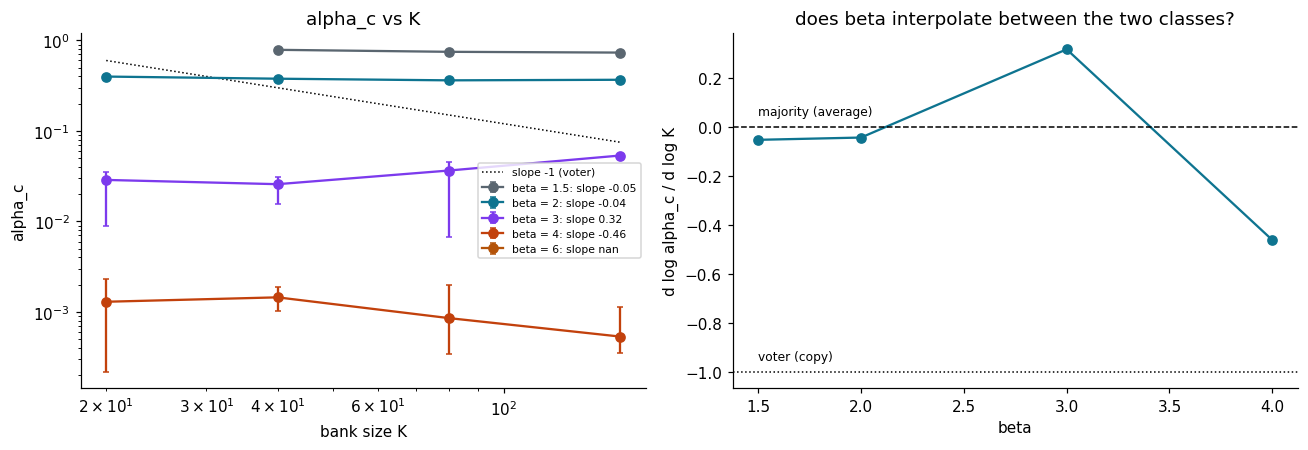

slopes {1.5: np.float64(-0.05), 2.0: np.float64(-0.04), 3.0: np.float64(0.32), 4.0: np.float64(-0.46), 6.0: np.float64(nan)}


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
slopes = []
bcols = ['#5a6670', '#0e7490', '#7c3aed', '#c2410c', '#b45309']
for bi, b in enumerate(betas):
    y = AC[:, bi]; ok = np.isfinite(y) & (y > 0)
    if ok.sum() >= 2:
        s, c = np.polyfit(np.log(Ks[ok]), np.log(y[ok]), 1)
    else:
        s = np.nan
    slopes.append(s)
    ax[0].errorbar(Ks, y, yerr=[y - lo[:, bi], hi[:, bi] - y], fmt='o-', color=bcols[bi], capsize=2, label=f'beta = {b:g}: slope {s:.2f}')
kk = np.array([20, 160])
ax[0].plot(kk, 0.6 * (kk / 20.0) ** -1, 'k:', lw=1, label='slope -1 (voter)')
ax[0].set(xscale='log', yscale='log', xlabel='bank size K', ylabel='alpha_c', title='alpha_c vs K')
ax[0].legend(fontsize=7)
ax[1].plot(betas, slopes, 'o-', color='#0e7490')
ax[1].axhline(-1, color='k', ls=':', lw=1); ax[1].axhline(0, color='k', ls='--', lw=1)
ax[1].text(betas[0], -0.95, 'voter (copy)', fontsize=8); ax[1].text(betas[0], 0.05, 'majority (average)', fontsize=8)
ax[1].set(xlabel='beta', ylabel='d log alpha_c / d log K', title='does beta interpolate between the two classes?')
fig.tight_layout(); fig.savefig(FIG / 'nb03_alphac_vs_K.png'); plt.show()
print('slopes', dict(zip(betas.tolist(), np.round(slopes, 2))))

## Reading

**The voter half of the hypothesis is FALSE. The majority half holds.**

1. **Low beta (1.5, 2): majority class.** alpha_c is finite and nearly independent of K (slopes -0.05 and -0.04): alpha_c ~ 0.74 at beta = 1.5 and ~ 0.37 at beta = 2 for K = 160. The curves steepen with K. This is a genuine transition, and it is robust to run length (K = 160 ran 640 generations, K = 20 ran 300).
2. **High beta (6): no collapse at all within 4K generations, even at alpha = 0.** This is not voter behaviour. Voter copying picks a random *stored* pattern, but here the query comes from the *environment*, which is balanced. Sharp retrieval returns the stored point nearest the query, so each side is replenished by its own queries. Consensus needs averaging.
3. **alpha_c(beta) falls steeply:** about 0.74, 0.37, 0.03, 0.001 and 0 for beta = 1.5, 2, 3, 4, 6.
4. **Intermediate beta (3, 4): not trustworthy yet.** The curves are noisy and non-monotone, and the bootstrap intervals are wide. At beta = 3, alpha_c *grows* with K (0.029 -> 0.054) while the runs also get longer, so the boundary may still be moving in time. The paper's own law says beta sets the clock: at high beta, collapse at alpha = 0 may simply take longer than the run.

**The open question that decides the paper:** is alpha_c(beta) at high beta a phase boundary, or a time-scale boundary? Test: alpha_c against run length (T = 300, 1000, 3000 generations) at beta = 3, 4, 6 and K = 40.